# Aligning and Voting Across Transcription Engines

Companion notebook. Change the engines and watch the ensemble stop working.

Standard library plus `matplotlib`. No API key, no accounts.

## 1 · Measuring, so the claims are checkable

In [1]:
from collections import Counter
from itertools import combinations

def levenshtein(a, b):
    if len(a) < len(b):
        a, b = b, a
    prev = list(range(len(b) + 1))
    for i, ca in enumerate(a, 1):
        cur = [i]
        for j, cb in enumerate(b, 1):
            cur.append(min(prev[j] + 1, cur[j - 1] + 1, prev[j - 1] + (ca != cb)))
        prev = cur
    return prev[-1]

def cer(ref, hyp):
    return levenshtein(list(ref), list(hyp)) / max(1, len(ref))

REF = "the council approved the drainage works on the north road in march"
print("reference:", REF)

reference: the council approved the drainage works on the north road in march


## 2 · Three engines, each wrong somewhere else

In [2]:
def vote(hypotheses):
    """Positional plurality vote. Assumes equal token counts — see section 4."""
    out = []
    for slot in zip(*(h.split() for h in hypotheses)):
        token, n = Counter(slot).most_common(1)[0]
        out.append(token if n >= 2 else slot[0])
    return " ".join(out)

DIVERSE = {
    "A": "the council aproved the drainage works on the north road in march",
    "B": "the council approved the drainage vvorks on the north road in march",
    "C": "the council approved the drainage works on the north road in rnarch",
}
for k, h in DIVERSE.items():
    print(f"engine {k}: CER={cer(REF, h):.4f}")

voted = vote(list(DIVERSE.values()))
print(f"\nvoted    : CER={cer(REF, voted):.4f}  {voted}")
print(f"best single: {min(cer(REF, h) for h in DIVERSE.values()):.4f}")

engine A: CER=0.0152
engine B: CER=0.0303
engine C: CER=0.0303

voted    : CER=0.0000  the council approved the drainage works on the north road in march
best single: 0.0152


Better than the **best** engine, not just the average. That is the property worth
paying for.

**Try it.** Move two engines' errors onto the same word. The vote stops helping
immediately — you do not need all three to collide, only two.

## 3 · When the engines share a confusion

In [3]:
SIMILAR = {
    "A": "the council approved the drainage works on the north road in rnarch",
    "B": "the council aproved the drainage works on the north road in rnarch",
    "C": "the council approved the drainage vvorks on the north road in rnarch",
}
for k, h in SIMILAR.items():
    print(f"engine {k}: CER={cer(REF, h):.4f}")

v2 = vote(list(SIMILAR.values()))
print(f"\nvoted    : CER={cer(REF, v2):.4f}  {v2}")
print(f"best single: {min(cer(REF, h) for h in SIMILAR.values()):.4f}")
print("\nthe shared rn/m reading wins 3-0. Voting has no notion of truth,")
print("only of agreement.")

engine A: CER=0.0303
engine B: CER=0.0455
engine C: CER=0.0606

voted    : CER=0.0303  the council approved the drainage works on the north road in rnarch
best single: 0.0303

the shared rn/m reading wins 3-0. Voting has no notion of truth,
only of agreement.


## 4 · Measure independence before building anything

In [4]:
def wrong_positions(ref, hyp):
    r, h = ref.split(), hyp.split()
    return {i for i in range(min(len(r), len(h))) if r[i] != h[i]}

def independence(ref, engines, label):
    print(label)
    wrong = {k: wrong_positions(ref, h) for k, h in engines.items()}
    for a, b in combinations(engines, 2):
        both = wrong[a] & wrong[b]
        same = {i for i in both if engines[a].split()[i] == engines[b].split()[i]}
        print(f"   {a}&{b}: both wrong at {sorted(both) or '—'}"
              f"   identically wrong at {sorted(same) or '—'}")
    union = set().union(*wrong.values())
    floor = {i for i in union if sum(i in w for w in wrong.values()) >= 2}
    print(f"   majority-wrong positions: {sorted(floor) or '—'}"
          f"  -> {'a hard floor on the ensemble' if floor else 'voting can fix everything'}\n")
    return floor

independence(REF, DIVERSE, "DIVERSE ENGINES")
independence(REF, SIMILAR, "SIMILAR ENGINES")

DIVERSE ENGINES
   A&B: both wrong at —   identically wrong at —
   A&C: both wrong at —   identically wrong at —
   B&C: both wrong at —   identically wrong at —
   majority-wrong positions: —  -> voting can fix everything

SIMILAR ENGINES
   A&B: both wrong at [11]   identically wrong at [11]
   A&C: both wrong at [11]   identically wrong at [11]
   B&C: both wrong at [11]   identically wrong at [11]
   majority-wrong positions: [11]  -> a hard floor on the ensemble



{11}

`both wrong` versus `identically wrong` is the distinction that matters. Two engines
failing differently at one position still leave a majority for the truth. Two failing
*the same way* form a bloc, and no voting rule can break it.

## 5 · The alignment trap

In [5]:
A = "the council approved the drainage works on the north road"
B = "the council approved drainage works on the north road"        # a word dropped
C = "the council appro ved the drainage works on the north road"   # a word split
SHORT_REF = A

print("token counts:", [len(h.split()) for h in (A, B, C)])
pv = vote([A, B, C])
print("\npositional vote:", pv)
print(f"  CER={cer(SHORT_REF, pv):.4f}   best single={min(cer(SHORT_REF,h) for h in (A,B,C)):.4f}")
print("\nthe ensemble is worse than doing nothing, and it fails silently:")
print("fluent output, one word short.")

token counts: [10, 9, 11]

positional vote: the council approved the drainage works on the north
  CER=0.0877   best single=0.0000

the ensemble is worse than doing nothing, and it fails silently:
fluent output, one word short.


## 6 · Align, then vote

In [6]:
def align_to_anchor(anchor, other, gap=-1.0, match=1.0, mismatch=-0.5):
    a, b = anchor.split(), other.split()
    n, m = len(a), len(b)
    S = [[0.0] * (m + 1) for _ in range(n + 1)]
    for i in range(1, n + 1): S[i][0] = S[i - 1][0] + gap
    for j in range(1, m + 1): S[0][j] = S[0][j - 1] + gap
    for i in range(1, n + 1):
        for j in range(1, m + 1):
            S[i][j] = max(S[i-1][j-1] + (match if a[i-1] == b[j-1] else mismatch),
                          S[i-1][j] + gap, S[i][j-1] + gap)
    out = [None] * n
    i, j = n, m
    while i > 0:
        score = match if (j > 0 and a[i-1] == b[j-1]) else mismatch
        if j > 0 and S[i][j] == S[i-1][j-1] + score:
            out[i-1] = b[j-1]; i, j = i-1, j-1
        elif S[i][j] == S[i-1][j] + gap:
            i -= 1
        else:
            j -= 1
    return out

def anchored_vote(anchor, others):
    cols = [anchor.split()] + [align_to_anchor(anchor, o) for o in others]
    out = []
    for k in range(len(cols[0])):
        slot = [c[k] for c in cols if c[k] is not None]
        token, n = Counter(slot).most_common(1)[0]
        out.append(token if n >= 2 else cols[0][k])
    return " ".join(out)

av = anchored_vote(A, [B, C])
print("anchored vote:", av)
print(f"  CER={cer(SHORT_REF, av):.4f}")
print("\nB's dropped word becomes an abstention, not a shift.")

anchored vote: the council approved the drainage works on the north road
  CER=0.0000

B's dropped word becomes an abstention, not a shift.


**Try it.** Set `gap=-0.1` (very cheap to skip a token) and re-run. The aligner
starts skipping tokens to chase matches further along, and the vote degrades. The
gap penalty is the knob that matters; a value near the mismatch cost is a sane start.

In [7]:
for g in (-0.1, -0.5, -1.0, -3.0):
    out = []
    cols = [A.split()] + [align_to_anchor(A, o, gap=g) for o in (B, C)]
    for k in range(len(cols[0])):
        slot = [c[k] for c in cols if c[k] is not None]
        t, n = Counter(slot).most_common(1)[0]
        out.append(t if n >= 2 else cols[0][k])
    print(f"gap={g:>5}  CER={cer(SHORT_REF, ' '.join(out)):.4f}")

gap= -0.1  CER=0.0000
gap= -0.5  CER=0.0000
gap= -1.0  CER=0.0000
gap= -3.0  CER=0.0000


## 7 · How the gain depends on error overlap

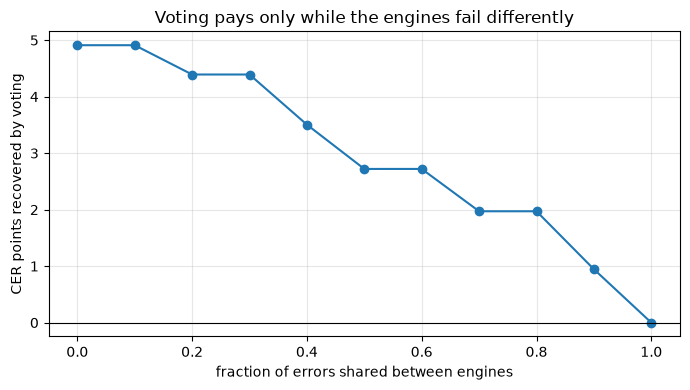

In [8]:
import random
import matplotlib.pyplot as plt

def synth(ref, n_engines=3, err_rate=0.10, overlap=0.0, seed=0):
    """Engines that each corrupt `err_rate` of tokens, sharing `overlap` of them."""
    rng = random.Random(seed)
    toks = ref.split()
    idx = list(range(len(toks)))
    n_err = max(1, int(len(toks) * err_rate))
    shared = rng.sample(idx, int(n_err * overlap))
    out = []
    for e in range(n_engines):
        own = rng.sample([i for i in idx if i not in shared], n_err - len(shared))
        bad = set(shared) | set(own)
        out.append(" ".join("###" if i in bad else t for i, t in enumerate(toks)))
    return out

LONG = " ".join(["the council approved the drainage works on the north road"] * 6)
xs, gains = [], []
for ov in [i / 10 for i in range(11)]:
    best_l, vote_l = [], []
    for seed in range(25):
        hyps = synth(LONG, overlap=ov, seed=seed)
        best_l.append(min(cer(LONG, h) for h in hyps))
        vote_l.append(cer(LONG, vote(hyps)))
    xs.append(ov)
    gains.append((sum(best_l)/len(best_l) - sum(vote_l)/len(vote_l)) * 100)

plt.figure(figsize=(7, 4))
plt.plot(xs, gains, "o-")
plt.axhline(0, color="k", lw=.8)
plt.xlabel("fraction of errors shared between engines")
plt.ylabel("CER points recovered by voting")
plt.title("Voting pays only while the engines fail differently")
plt.grid(alpha=.3); plt.tight_layout(); plt.show()

The gain falls to nothing as the engines converge. **Diversity is the resource being
spent** — two variants of one model with different seeds will buy you almost nothing,
however carefully the votes are counted.